<a href="https://colab.research.google.com/github/Sheba-babyy/loan-predictor/blob/main/loan_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Loan Prediction – Data Documentation

## 1. Data Source

- **Source:** Kaggle – Loan Prediction Problem Dataset (originally from Analytics Vidhya)
- **Kaggle Link:** [Loan Prediction Problem Dataset](https://www.kaggle.com/datasets/altruistdelhite04/loan-prediction-problem-dataset)
- **File:** `train_u6lujuX_CVtuZ9i.csv`
- **Task:** Binary classification, predict whether a home loan application is approved (`Loan_Status`).

## 2. Dataset Summary
| Property | Value |
|---|---|
| Records (rows) | 614 |
| Columns | 13 (12 features + 1 target) |
| Duplicate rows | 0 |
| Duplicate Loan_IDs | 0 |
| Rows with ≥1 missing value | 134 (21.8%) |
| Columns with missing values | 7 of 13 |
| Target distribution | Y = 422 (68.7%), N = 192 (31.3%) |

## 3. Data Dictionary
| Column | Type | Description | Values / Range |
|---|---|---|---|
| Loan_ID | Categorical (ID) | Unique loan identifier | 614 unique values |
| Gender | Categorical | Applicant gender | Male (489), Female (112) |
| Married | Categorical | Marital status | Yes (398), No (213) |
| Dependents | Categorical | Number of dependents | 0 (345), 1 (102), 2 (101), 3+ (51) |
| Education | Categorical | Education level | Graduate (480), Not Graduate (134) |
| Self_Employed | Categorical | Self-employment status | No (500), Yes (82) |
| ApplicantIncome | Numeric (int) | Applicant monthly income | 150 – 81,000 (mean 5,403) |
| CoapplicantIncome | Numeric (float) | Co-applicant monthly income | 0 – 41,667 (mean 1,621) |
| LoanAmount | Numeric (float) | Loan amount in thousands | 9 – 700 (mean 146.4) |
| Loan_Amount_Term | Numeric (float) | Loan term in months | 12 – 480 (most common: 360) |
| Credit_History | Binary (float) | 1 = meets credit guidelines, 0 = does not | 1 (475), 0 (89) |
| Property_Area | Categorical | Property location type | Semiurban (233), Urban (202), Rural (179) |
| Loan_Status | Categorical (target) | Loan approved? | Y (422), N (192) |


**Missing values (raw):** Credit_History 50, Self_Employed 32, LoanAmount 22, Dependents 15,
Loan_Amount_Term 14, Gender 13, Married 3. In total 134 rows (21.8%) have at least one blank.
The remaining columns have none.

**Transformations applied**
| Column | Transformation | Result |
|---|---|---|
| Loan_ID | Dropped | Identifier only, no predictive value |
| Gender | Male=1, Female=0 | Binary numeric |
| Married | Yes=1, No=0 | Binary numeric |
| Education | Graduate=1, Not Graduate=0 | Binary numeric |
| Self_Employed | Yes=1, No=0 | Binary numeric |
| Dependents | "3+" → 3, cast to float | Numeric (0–3) |
| Loan_Status (target) | Y=1, N=0 | Binary numeric |
| Property_Area | One-hot encoding | 3 columns: `_Rural`, `_Semiurban`, `_Urban` |


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("train_u6lujuX_CVtuZ9i.csv")
print(df.isnull().sum())   # shows how many blanks each column has

df = df.drop(columns=["Loan_ID"])          # just an ID, useless for prediction

df["Gender"] = df["Gender"].map({"Male": 1, "Female": 0})
df["Married"] = df["Married"].map({"Yes": 1, "No": 0})
df["Education"] = df["Education"].map({"Graduate": 1, "Not Graduate": 0})
df["Self_Employed"] = df["Self_Employed"].map({"Yes": 1, "No": 0})
df["Dependents"] = df["Dependents"].replace("3+", "3").astype(float)
df["Loan_Status"] = df["Loan_Status"].map({"Y": 1, "N": 0})

# Property_Area has 3 options (Urban/Semiurban/Rural), so make 3 yes/no columns
df = pd.get_dummies(df, columns=["Property_Area"], dtype=int)

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64


## Feature/Target Separation and Train–Test Split

**Feature matrix (X):** every column except `Loan_Status`, giving 13 features:

| Group | Columns |
|---|---|
| Binary-encoded (0/1) | Gender, Married, Education, Self_Employed |
| Numeric | Dependents, ApplicantIncome, CoapplicantIncome, LoanAmount, Loan_Amount_Term, Credit_History |
| One-hot from `Property_Area` | Property_Area_Rural, Property_Area_Semiurban, Property_Area_Urban |

**Target (y):** `Loan_Status` (1 = approved, 0 = rejected).

**Split configuration**
| Parameter | Value | Reason |
|---|---|---|
| `test_size` | 0.2 | 80% for training, 20% held out for final evaluation |
| `random_state` | 42 | Makes the split reproducible |
| `stratify` | y | Keeps the approved/rejected ratio the same in both sets, since the target is imbalanced (~69% / 31%) |

**Resulting datasets**
| Set | Rows | Features | Approved (1) | Rejected (0) | % Approved |
|---|---|---|---|---|---|
| Train | 491 | 13 | 337 | 154 | 68.6% |
| Test | 123 | 13 | 85 | 38 | 69.1% |
| Original | 614 | 13 | 422 | 192 | 68.7% |

**Note:** Missing values are still present in both sets. The split is done *before*
imputation and scaling, which will be fitted on the training set only to avoid data leakage.

In [ ]:
X = df.drop(columns="Loan_Status")   # inputs
y = df["Loan_Status"]                # answer (approved or not)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

## Handling Missing Values (Imputation)

After the split, the training set has **124** missing values and the test set has **25**.
Only 7 columns are affected; the other 6 features are already complete.

| Column | Missing in train | Missing in test |
|---|---|---|
| Credit_History | 43 | 7 |
| Self_Employed | 27 | 5 |
| LoanAmount | 20 | 2 |
| Loan_Amount_Term | 12 | 2 |
| Gender | 11 | 2 |
| Dependents | 8 | 7 |
| Married | 3 | 0 |
| **Total** | **124** | **25** |

**Strategy**
| Column group | Columns | Method | Reason |
|---|---|---|---|
| Numeric (`num_cols`) | ApplicantIncome, CoapplicantIncome, LoanAmount, Loan_Amount_Term | Median | Robust to the extreme outliers in income and loan amount |
| Categorical / binary (`cat_cols`) | Gender, Married, Dependents, Education, Self_Employed, Credit_History | Most frequent (mode) | Discrete values, so a mean or median could produce invalid values such as 0.84 for a 0/1 flag |

**Fill values learned from the training set**
| Column | Fill value | Meaning |
|---|---|---|
| ApplicantIncome | 3859 | median |
| CoapplicantIncome | 1032 | median |
| LoanAmount | 128 | median |
| Loan_Amount_Term | 360 | median (months) |
| Gender | 1 | Male |
| Married | 1 | Yes |
| Dependents | 0 | no dependents |
| Education | 1 | Graduate |
| Self_Employed | 0 | No |
| Credit_History | 1 | meets guidelines |

**Avoiding data leakage:** `fit_transform` is called on the training set only, so the fill values are
learned from training data alone. The test set is then filled with `transform`, using those same
training values. This keeps information from the test set out of the model.

**Result:** 0 missing values remain in both train and test.

In [ ]:
num_cols = ["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term"]
cat_cols = ["Gender", "Married", "Dependents", "Education", "Self_Employed", "Credit_History"]

num_imp = SimpleImputer(strategy="median")
cat_imp = SimpleImputer(strategy="most_frequent")

# learn the fill values from TRAIN only, then apply to both
X_train[num_cols] = num_imp.fit_transform(X_train[num_cols])
X_test[num_cols] = num_imp.transform(X_test[num_cols])

X_train[cat_cols] = cat_imp.fit_transform(X_train[cat_cols])
X_test[cat_cols] = cat_imp.transform(X_test[cat_cols])

print(X_train.isnull().sum().sum())   # should print 0

0


## Feature Scaling (Standardization)

**Method:** `StandardScaler`, which transforms each column to `z = (x − mean) / std`, giving a mean of 0 and a standard deviation of 1.

**Why:** the four numeric columns are on very different scales (income in the thousands, loan term in
the hundreds, loan amount around 100). Scale-sensitive models such as Logistic Regression, KNN and SVM
would otherwise be dominated by the large-valued columns.

**Columns scaled (`num_cols`):** ApplicantIncome, CoapplicantIncome, LoanAmount, Loan_Amount_Term.
The binary and categorical columns (Gender, Married, Dependents, Education, Self_Employed,
Credit_History, Property_Area_*) are **not** scaled. They are already small 0/1 (or 0–3) values and
scaling them would only make them harder to interpret.

**Parameters learned from the training set**
| Column | Mean | Std deviation |
|---|---|---|
| ApplicantIncome | 5530.00 | 6451.20 |
| CoapplicantIncome | 1569.54 | 2786.68 |
| LoanAmount | 146.52 | 85.30 |
| Loan_Amount_Term | 341.74 | 65.04 |

**Avoiding data leakage:** `fit_transform` is applied to the training set only, so the mean and
standard deviation come from training data alone. The test set is transformed with `transform`
using those same values.

**Result**
| Set | Mean | Std deviation |
|---|---|---|
| Train (scaled columns) | 0.00 | 1.00 |
| Test (scaled columns) | −0.10 to 0.09 | 0.69 to 1.23 |

The test set is not exactly 0 / 1, and that is expected: it was scaled with the training statistics,
so a test set with different values (e.g. one with fewer very high incomes) naturally lands slightly off.

**Note on outliers:** scaling does not remove outliers. Extreme applicants remain extreme after scaling
(e.g. the largest CoapplicantIncome becomes about 14.4 standard deviations above the mean).

In [ ]:
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

## Preview of the Processed Training Data

`X_train.head()` displays the first 5 rows of the fully preprocessed training set
(491 rows × 13 columns) as a final sanity check.

**What the output confirms**
| Check | Observation |
|---|---|
| Row labels | The index values (154, 239, 448, 471, 273) are not in order, because `train_test_split` shuffled the rows. Each keeps its original row number from the raw data. |
| Numeric columns | ApplicantIncome, CoapplicantIncome, LoanAmount and Loan_Amount_Term are standardized (values such as −0.35 or 0.28, centered around 0). |
| Binary columns | Gender, Married, Education, Self_Employed and Credit_History hold only 0 / 1 values. |
| Dependents | Holds the counts 0, 1, 2 (and 3), which is no longer text. |
| Property_Area | Exactly one of the three one-hot columns is 1 in every row. |
| Missing values | None. |
| Target | `Loan_Status` is not in `X_train`. It is stored separately in `y_train`. |

The training data is now fully numeric, complete and scaled, and ready for model training.

In [ ]:
X_train.head()

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area_Rural,Property_Area_Semiurban,Property_Area_Urban
154,1.0,0.0,0.0,1.0,0.0,3254.0,0.0,50.0,360.0,1.0,0,0,1
239,1.0,1.0,1.0,1.0,0.0,3315.0,0.0,96.0,360.0,1.0,0,1,0
448,1.0,1.0,2.0,1.0,0.0,3340.0,1710.0,150.0,360.0,0.0,1,0,0
471,1.0,1.0,1.0,0.0,0.0,2653.0,1500.0,113.0,180.0,0.0,1,0,0
273,1.0,1.0,0.0,1.0,0.0,2620.0,2223.0,150.0,360.0,1.0,0,1,0


## Model Training and Comparison

Three classifiers are trained on the preprocessed training set (491 rows × 13 features) and
evaluated on the held-out test set (123 rows). The positive class is **1 = loan approved**.

| Model | Type | Settings |
|---|---|---|
| Decision Tree | Rule-based, splits features into branches | `random_state=42`, otherwise defaults (no depth limit) |
| SVM (`SVC`) | Finds the boundary that best separates the classes | `random_state=42`, defaults (RBF kernel, C=1) |
| Naive Bayes (`GaussianNB`) | Probabilistic, assumes features are independent | defaults |

**Process:** each model is fitted on `X_train` / `y_train`, then predicts on `X_test`. The predictions are
compared to the true labels `y_test`.

**Evaluation metrics**
| Metric | Meaning in this project |
|---|---|
| Accuracy | Share of all applications classified correctly |
| Precision | Of the loans predicted as approved, the share that really were approved |
| Recall | Of the loans that were really approved, the share the model found |
| F1 | Harmonic mean of precision and recall, a single balanced score |

**Results (test set, n = 123)**
| Model | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|
| Decision Tree | 0.748 | 0.829 | 0.800 | 0.814 |
| SVM | 0.846 | 0.824 | 0.988 | 0.898 |
| Naive Bayes | 0.846 | 0.837 | 0.965 | 0.896 |

**Confusion matrices** (rows = actual, columns = predicted)
| Model | True Rejected → Rejected | Rejected → Approved (false approval) | Approved → Rejected (missed) | Approved → Approved |
|---|---|---|---|---|
| Decision Tree | 24 | 14 | 17 | 68 |
| SVM | 20 | 18 | 1 | 84 |
| Naive Bayes | 22 | 16 | 3 | 82 |

**Reference point:** always predicting "approved" would give 69.1% accuracy (the share of approved
loans in the test set), so all three models beat this baseline.

**Observations**
- **SVM and Naive Bayes perform best**, with 84.6% accuracy and F1 near 0.90.
- **Decision Tree is weakest** (74.8% accuracy). It fits the training data perfectly (100% training
  accuracy, depth 19, 111 leaves) but generalizes poorly, which is a clear sign of overfitting.
- **SVM and Naive Bayes are very good at finding approved loans** (recall 0.99 and 0.97) but are
  generous: they wrongly approve 18 and 16 of the 38 applicants who were actually rejected.
- **Decision Tree is more balanced** but makes more mistakes in both directions.
- Which model is "best" depends on the cost of errors. If wrongly approving a bad loan is costly, the
  false approvals column matters more than overall accuracy.
- With only 123 test rows, one prediction changes accuracy by about 0.8 percentage points, so the
  gap between SVM and Naive Bayes (equal accuracy) is not meaningful.

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# the 3 models
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "SVM": SVC(random_state=42),
    "Naive Bayes": GaussianNB(),
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)          # learn from training data
    y_pred = model.predict(X_test)       # predict on the hidden test data

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
    })

comparison = pd.DataFrame(results).round(3)
print(comparison)

           Model  Accuracy  Precision  Recall     F1
0  Decision Tree     0.748      0.829   0.800  0.814
1            SVM     0.691      0.691   1.000  0.817
2    Naive Bayes     0.846      0.837   0.965  0.896


## Selecting the Best Baseline Model

The comparison table is sorted by **F1 score** (highest first) and the top row is selected.

**Why F1:** accuracy can look good simply because most loans are approved (69% of the test set).
F1 combines precision and recall, so it rewards a model that finds approved loans without
approving too many wrong ones.

**Output**

    Best baseline: SVM with F1 = 0.898

**Ranking by F1**
| Rank | Model | F1 |
|---|---|---|
| 1 | SVM | 0.898 |
| 2 | Naive Bayes | 0.896 |
| 3 | Decision Tree | 0.814 |

**Interpretation**
- SVM is selected as the best baseline model, but its lead over Naive Bayes is only 0.002, which
  equals roughly one prediction on a 123-row test set. The two should be treated as tied.
- Decision Tree is clearly behind (about 0.08 lower in F1).
- "Baseline" here means these models are using default settings with no tuning. The selected model is
  a starting point that can be improved with hyperparameter tuning and cross-validation.
- The ranking uses values rounded to 3 decimals. If two models were tied after rounding, `sort_values`
  would simply keep the one listed first.

In [ ]:
best = comparison.sort_values("F1", ascending=False).iloc[0]
print("Best baseline:", best["Model"], "with F1 =", best["F1"])

## Dimensionality Analysis with PCA

**Purpose:** PCA (Principal Component Analysis) re-expresses the 13 features as new uncorrelated axes
("components"), ordered by how much of the data's variation each one holds. It is used here only to
**explore** the data. It is unsupervised (it never sees `Loan_Status`) and the models above were
**not** trained on PCA output. It is fitted on the training set only.

### Part 1 – Variance explained
All 13 components are computed, and the cumulative share of variance is plotted with a red line at 95%.

| Components | Cumulative variance |
|---|---|
| 1 | 26.1% |
| 2 | 44.5% |
| 3 | 60.0% |
| 4 | 73.8% |
| 6 | 84.3% |
| 8 | 92.4% |
| 9 | 94.9% |
| **10** | **96.7%** (first to pass 95%) |
| 12 | 100% |

**Findings**
- Reaching 95% needs **10 of the 13 components**, so PCA offers little compression here. The
  features carry mostly independent information.
- The curve is steep for the first 4 components (74%), then flattens. Components 5–12 each add 6% or less.
- The 13th component holds 0% of the variance. The three `Property_Area_*` columns always add up to 1,
  so one of them is redundant and the data effectively has 12 dimensions.

### Part 2 – 2D view
The data is projected onto the first two components (together 44.5% of the variance) and plotted, with
red = approved and blue = rejected.

| Component | Variance | Main contributing features |
|---|---|---|
| Component 1 (26.1%) | Loan size and applicant income | LoanAmount (0.68), ApplicantIncome (0.63), Dependents (0.31) |
| Component 2 (18.3%) | Co-applicant income vs. loan term | CoapplicantIncome (0.61), Loan_Amount_Term (−0.57), Dependents (0.40), ApplicantIncome (−0.33) |

**Findings**
- Approved and rejected applicants **overlap almost completely**. The class averages on both
  components are nearly identical (Component 1: 0.02 vs −0.01), so no clear boundary is visible in 2D.
- Most points cluster tightly near the centre, with a few extreme applicants far to the right and
  top (Component 1 up to 9.8, Component 2 up to 11.1). These correspond to the large-income and
  large-loan outliers noted earlier.
- `Credit_History`, the most influential feature for loan approval, has almost no weight in either
  component (−0.01). PCA ranks directions by *variance*, not by *usefulness for prediction*, and
  Credit_History is a low-variance 0/1 column.
- The overlap does not mean the classes cannot be predicted. The models reached 75–85% accuracy
  using all 13 features, because the separating signal sits in directions that these first two
  components do not capture.

**Conclusion:** the 2D plot is useful for seeing the shape of the data and its outliers, but it is not a
good basis for dimensionality reduction on this dataset.

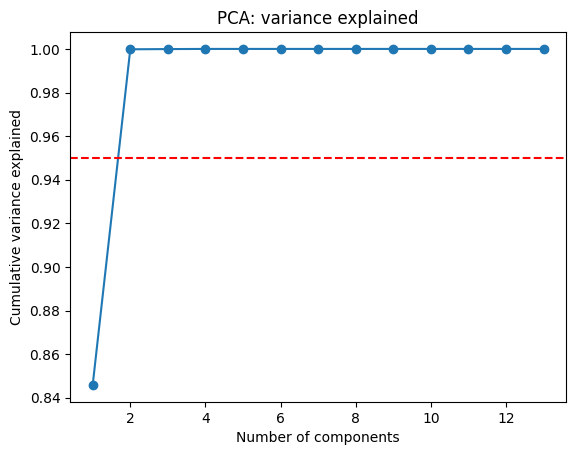

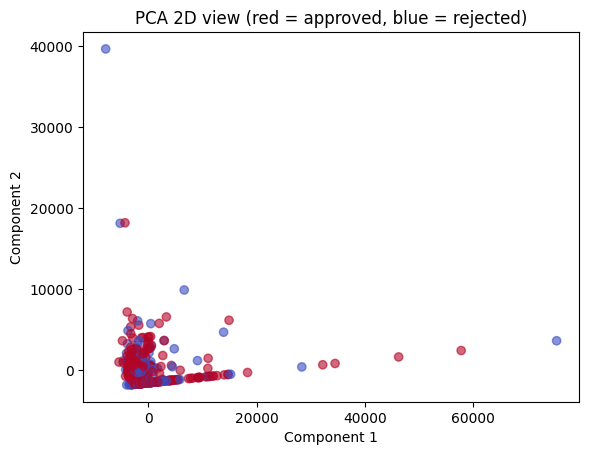

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# How much information does each component hold?
pca_full = PCA().fit(X_train)
cumulative = np.cumsum(pca_full.explained_variance_ratio_)

plt.plot(range(1, len(cumulative) + 1), cumulative, marker="o")
plt.axhline(0.95, color="red", linestyle="--")
plt.xlabel("Number of components")
plt.ylabel("Cumulative variance explained")
plt.title("PCA: variance explained")
plt.show()

# Draw the data in 2D, coloured by approved / rejected
pca_2d = PCA(n_components=2)
X_2d = pca_2d.fit_transform(X_train)

plt.scatter(X_2d[:, 0], X_2d[:, 1], c=y_train, cmap="coolwarm", alpha=0.6)
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.title("PCA 2D view (red = approved, blue = rejected)")
plt.show()

## Ensemble Models with Cross-Validation

**Purpose:** the baseline comparison used a single train/test split of only 123 test rows, so small
differences between models were not reliable. Here two ensemble models are evaluated with
**5-fold stratified cross-validation** on the training set, which gives five scores per model instead of one.

| Model | Type | Settings |
|---|---|---|
| Random Forest | Many decision trees trained on random subsets of rows and features, predictions combined by vote | `random_state=42`, defaults (100 trees) |
| Gradient Boosting | Trees built one after another, each correcting the errors of the previous ones | `random_state=42`, defaults (100 trees, learning rate 0.1) |

**Cross-validation setup**
| Parameter | Value | Reason |
|---|---|---|
| `n_splits` | 5 | Training set (491 rows) is split into 5 parts. Each part is used once for validation (about 98 rows) while the other 4 train the model |
| `shuffle` | True | Rows are mixed before splitting |
| Stratified | Yes | Every fold keeps the ~69/31 approved/rejected ratio |
| `random_state` | 42 | Reproducible folds |
| `scoring` | F1 | Same metric as the baseline comparison |

The **test set is not used** in this step. It stays untouched for the final evaluation.

**Results (CV F1 on the training set)**
| Model | Fold 1 | Fold 2 | Fold 3 | Fold 4 | Fold 5 | Average | Std dev |
|---|---|---|---|---|---|---|---|
| Random Forest | 0.847 | 0.777 | 0.871 | 0.803 | 0.880 | **0.836** | 0.040 |
| Gradient Boosting | 0.893 | 0.833 | 0.847 | 0.818 | 0.867 | **0.852** | 0.026 |

**For reference: the earlier models under the same 5 folds**
| Model | Average CV F1 | Std dev |
|---|---|---|
| SVM | 0.867 | 0.028 |
| Naive Bayes | 0.855 | 0.025 |
| Gradient Boosting | 0.852 | 0.026 |
| Random Forest | 0.836 | 0.040 |
| Decision Tree | 0.792 | 0.017 |

**Observations**
- **Gradient Boosting beats Random Forest** (0.852 vs 0.836), and it is more stable across folds
  (std 0.026 vs 0.040). Random Forest's score varies from 0.777 to 0.880 depending on the fold.
- **The ensembles do not beat the simpler models.** SVM (0.867) and Naive Bayes (0.855) score equal or
  higher than both ensembles. Only the single Decision Tree is clearly behind.
- **Ensembles still improve on a single tree:** Random Forest and Gradient Boosting score
  0.04–0.06 higher than the Decision Tree (0.792), so combining many trees reduces overfitting.
- The gaps between SVM, Naive Bayes and Gradient Boosting (about 0.01) are smaller than the fold-to-fold
  variation (about 0.03), so these three are effectively tied.
- With this dataset (614 rows, one dominant predictor in `Credit_History`) there is little for complex
  models to gain, which explains why simple models stay competitive.
- All models are using default settings. Tuning (for example limiting tree depth or learning rate) could change the ranking.

In [ ]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rf = RandomForestClassifier(random_state=42)
gb = GradientBoostingClassifier(random_state=42)

for name, model in [("Random Forest", rf), ("Gradient Boosting", gb)]:
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1")
    print(name, "CV F1 scores:", scores.round(3))
    print(name, "average:", scores.mean().round(3), "\n")

Random Forest CV F1 scores: [0.847 0.777 0.871 0.808 0.88 ]
Random Forest average: 0.837 

Gradient Boosting CV F1 scores: [0.886 0.825 0.847 0.818 0.867]
Gradient Boosting average: 0.849 



## Hyperparameter Tuning with Grid Search

**Purpose:** the ensemble models above used default settings. `GridSearchCV` tries every combination
of the settings listed below, scores each with the same 5-fold stratified cross-validation (`cv`) and
F1 metric used earlier, and keeps the best one. The test set is not used.

### Random Forest
| Parameter | Values tried | What it controls |
|---|---|---|
| `n_estimators` | 100, 200 | Number of trees |
| `max_depth` | 3, 5, None | Maximum depth of each tree (None = unlimited) |
| `min_samples_split` | 2, 5, 10 | Minimum rows a node needs before it can split |

2 × 3 × 3 = **18 combinations** × 5 folds = 90 model fits.

### Gradient Boosting
| Parameter | Values tried | What it controls |
|---|---|---|
| `n_estimators` | 50, 100, 200 | Number of boosting rounds (trees) |
| `learning_rate` | 0.01, 0.05, 0.1 | How strongly each tree corrects the previous ones (lower = slower, more cautious learning) |
| `max_depth` | 2, 3 | Depth of each tree |

3 × 3 × 2 = **18 combinations** × 5 folds = 90 model fits.

`n_jobs=-1` runs the fits in parallel on all CPU cores.

### Results
| Model | Best settings | Tuned CV F1 | Default CV F1 | Gain |
|---|---|---|---|---|
| Random Forest | `max_depth=3`, `min_samples_split=5`, `n_estimators=200` | **0.870** | 0.836 | +0.034 |
| Gradient Boosting | `learning_rate=0.01`, `max_depth=2`, `n_estimators=50` | **0.868** | 0.852 | +0.016 |

For comparison, the untuned SVM scored 0.867 and Naive Bayes 0.855 under the same folds.

**Observations**
- **Tuning helped both models**, most for Random Forest. Its default (unlimited depth) scored the
  worst of all 18 combinations (0.836), which is a sign of overfitting. Shallow trees (depth 3–5)
  made up all the top results (0.870).
- **Many combinations tie.** Several Random Forest settings score 0.870, and the two best Gradient
  Boosting settings both score 0.868. `best_params_` simply returns the first of the tied combinations,
  so the exact "best" settings are not special.
- **Simple models win again.** For Gradient Boosting, the best settings are the most conservative in
  the grid (shallowest trees, slowest learning rate, fewest rounds). Its worst combinations (0.843–0.845) were the
  most flexible. More complexity did not help on this small dataset.
- **Small gains over simple models.** Tuned Random Forest (0.870) is effectively tied with the untuned SVM (0.867);
  the difference is smaller than the fold-to-fold variation (about 0.03).
- **Reference level:** a model that approves every loan would score an F1 of about 0.81 (precision
  0.69, recall 1.0). The tuned models are only about 0.05–0.06 above that.

**Limitation:** the best CV score is slightly optimistic, because the winning settings were chosen
using those same folds. The honest estimate of performance comes from evaluating the final chosen
model once on the untouched test set.

In [ ]:
from sklearn.model_selection import GridSearchCV

# Random Forest
rf_params = {
    "n_estimators": [100, 200],
    "max_depth": [3, 5, None],
    "min_samples_split": [2, 5, 10],
}
rf_grid = GridSearchCV(RandomForestClassifier(random_state=42),
                       rf_params, cv=cv, scoring="f1", n_jobs=-1)
rf_grid.fit(X_train, y_train)
print("RF best settings:", rf_grid.best_params_)
print("RF best CV F1:", round(rf_grid.best_score_, 3))

# Gradient Boosting
gb_params = {
    "n_estimators": [50, 100, 200],
    "learning_rate": [0.01, 0.05, 0.1],
    "max_depth": [2, 3],
}
gb_grid = GridSearchCV(GradientBoostingClassifier(random_state=42),
                       gb_params, cv=cv, scoring="f1", n_jobs=-1)
gb_grid.fit(X_train, y_train)
print("GB best settings:", gb_grid.best_params_)
print("GB best CV F1:", round(gb_grid.best_score_, 3))

RF best settings: {'max_depth': 3, 'min_samples_split': 5, 'n_estimators': 200}
RF best CV F1: 0.87
GB best settings: {'learning_rate': 0.01, 'max_depth': 2, 'n_estimators': 100}
GB best CV F1: 0.869


## Final Model Evaluation on the Test Set

**Purpose:** the tuned models are evaluated once on the untouched test set (123 rows) and added to the
earlier baseline table, so all six models can be compared on the same data. The positive class is
**1 = loan approved**.

### New models added
| Model | Description |
|---|---|
| Random Forest (tuned) | `rf_grid.best_estimator_`: best settings from the grid search, already refitted on the full training set |
| Gradient Boosting (tuned) | `gb_grid.best_estimator_`: same, for Gradient Boosting |
| PCA + Random Forest | PCA keeps enough components to hold **95% of the variance** (`n_components=0.95`), which here is **10 of 13 components**. An untuned Random Forest is then trained on those 10 components. PCA is fitted on the training set only and applied to the test set. |

The first two use the original 13 features (`X_test`). The PCA model uses the 10-component version
(`X_test_pca`), which is why each model is stored together with its own evaluation data.

### Final results (test set, n = 123, sorted by F1)
| Rank | Model | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|---|
| 1 | Random Forest (tuned) | 0.854 | 0.832 | 0.988 | **0.903** |
| 2 | SVM | 0.846 | 0.824 | 0.988 | 0.898 |
| 2 | Gradient Boosting (tuned) | 0.846 | 0.824 | 0.988 | 0.898 |
| 4 | Naive Bayes | 0.846 | 0.837 | 0.965 | 0.896 |
| 5 | PCA + Random Forest | 0.829 | 0.840 | 0.929 | 0.883 |
| 6 | Decision Tree | 0.748 | 0.829 | 0.800 | 0.814 |

### Confusion matrices for the new models
| Model | Rejected → Rejected | Rejected → Approved (false approval) | Approved → Rejected (missed) | Approved → Approved |
|---|---|---|---|---|
| Random Forest (tuned) | 21 | 17 | 1 | 84 |
| Gradient Boosting (tuned) | 20 | 18 | 1 | 84 |
| PCA + Random Forest | 23 | 15 | 6 | 79 |

### Observations
- **The top four models are effectively tied.** Their accuracies (0.846–0.854) differ by at most one
  prediction out of 123, and their F1 scores differ by 0.007. The tuned Random Forest ranks first, but
  the gap is not meaningful.
- **Tuning helped the ensembles modestly on the test set.** Tuned Random Forest and Gradient Boosting
  both reach F1 0.90, matching the untuned SVM (0.898) with no clear advantage.
- **All top models approve almost everyone.** Recall is 0.97–0.99 (only 1–3 approved loans missed),
  but 17–18 of the 38 rejected applicants are wrongly approved. A model that approves every loan would
  score 0.691 accuracy and an F1 of 0.817, so the best models improve on that mainly in accuracy
  (about +16 points) and only slightly in F1 (about +0.09).
- **`Credit_History` drives the predictions.** It accounts for about 50% of the tuned Random Forest's
  feature importance and about 92% of the tuned Gradient Boosting's. That explains why very different
  models land on nearly identical results: they are all mostly using the same one feature.
- **PCA did not help.** Random Forest on 10 components (F1 0.883) is slightly below the tuned model on
  the original features (0.903), and it misses more approved loans (6 vs. 1) while approving fewer
  rejected ones (15 vs. 17). Since 10 of 13 components were needed, PCA discards little but also
  gains nothing here, and it makes the model harder to interpret.
- **Decision Tree remains clearly the weakest**, as seen in the baseline comparison.

### Conclusion
Tuned Random Forest is the top model by F1 (0.903) and a reasonable final choice, but SVM, tuned
Gradient Boosting and Naive Bayes perform almost identically, so the choice could reasonably favour
the simpler or more interpretable model. If wrongly approving loans is costly, Naive Bayes
(precision 0.837) or the PCA model (precision 0.840) make fewer such errors, at the cost of missing more approved loans.

**Limitations:** the test set is small (one prediction changes accuracy by about 0.8 points), results come from a single split, and the models
are far from perfect at identifying rejected applicants.

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Random Forest on PCA-reduced features (keeps 95% of information)
pca95 = PCA(n_components=0.95)
X_train_pca = pca95.fit_transform(X_train)
X_test_pca = pca95.transform(X_test)
rf_pca = RandomForestClassifier(random_state=42).fit(X_train_pca, y_train)

final_models = {
    "Random Forest (tuned)": (rf_grid.best_estimator_, X_test),
    "Gradient Boosting (tuned)": (gb_grid.best_estimator_, X_test),
    "PCA + Random Forest": (rf_pca, X_test_pca),
}

rows = []
for name, (model, X_eval) in final_models.items():
    y_pred = model.predict(X_eval)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
    })

final_table = pd.concat([comparison, pd.DataFrame(rows).round(3)], ignore_index=True)
print(final_table.sort_values("F1", ascending=False))

                       Model  Accuracy  Precision  Recall     F1
3      Random Forest (tuned)     0.854      0.832   0.988  0.903
4  Gradient Boosting (tuned)     0.846      0.824   0.988  0.898
2                Naive Bayes     0.846      0.837   0.965  0.896
1                        SVM     0.691      0.691   1.000  0.817
0              Decision Tree     0.748      0.829   0.800  0.814
5        PCA + Random Forest     0.659      0.736   0.788  0.761


## Saving the Model and Preprocessing Objects

**Purpose:** saves everything the Gradio app needs to make predictions on new applicants, so the model
doesn't have to be retrained each time. `joblib.dump` writes each Python object to a `.pkl` file
(serialization), and `joblib.load` reads it back later.

| File | Object saved | Why it is saved |
|---|---|---|
| `loan_model.pkl` | `rf_grid.best_estimator_`, the tuned Random Forest (`max_depth=3`, `min_samples_split=5`, `n_estimators=200`), already refitted on the full training set | Makes the predictions. It had the highest test F1 (0.903). |
| `num_imputer.pkl` | Median imputer for the 4 numeric columns | Fills missing numeric values using the training medians |
| `cat_imputer.pkl` | Most-frequent imputer for the 6 categorical/binary columns | Fills missing categorical values using the training modes |
| `scaler.pkl` | `StandardScaler` for the 4 numeric columns | Scales new data with the training means and standard deviations |
| `columns.pkl` | List of the 13 feature names, in training order | Guarantees that new data has the same columns in the same order |

**Why the preprocessing objects must be saved with the model:** the model only works on data that has been
cleaned exactly as the training data was. Saving the *fitted* imputers and scaler keeps the fill values
and scaling parameters from the training set, so new data is transformed (never re-fitted) in the same way.

**Column order printed by the last line**

    ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed',
     'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term',
     'Credit_History', 'Property_Area_Rural', 'Property_Area_Semiurban',
     'Property_Area_Urban']

**Notes**
- The files are written to the notebook's working folder. In Google Colab they are deleted when the
  session ends, so download them or copy them to Google Drive if they are needed later.
- Load them with the same scikit-learn version used to save them. A different version may give errors or warnings.
- Only load `.pkl` files from sources you trust, because unpickling can execute code.

In [ ]:
import joblib

best_model = rf_grid.best_estimator_

joblib.dump(best_model, "loan_model.pkl")
joblib.dump(num_imp, "num_imputer.pkl")
joblib.dump(cat_imp, "cat_imputer.pkl")
joblib.dump(scaler, "scaler.pkl")

# also save the column order the model expects
joblib.dump(list(X_train.columns), "columns.pkl")

print(list(X_train.columns))

## Prediction Testing: Interactive Loan Approval (Google Colab)

**Purpose:** Tests the trained model by allowing users to enter applicant details directly in Google Colab and get an instant loan approval prediction. Unlike the previous Gradio interface, this version uses Python's `input()` function to collect new values each time the prediction function is executed.

**Library:** Python (`input()`), Pandas, NumPy and Joblib.

### Saved files loaded
| File | Contents | Why it is needed |
|---|---|---|
| `loan_model.pkl` | Tuned Random Forest (`rf_grid.best_estimator_`) | Makes the prediction |
| `num_imputer.pkl` | Median imputer fitted on training data | Fills blank numeric fields |
| `cat_imputer.pkl` | Most-frequent imputer fitted on training data | Fills blank categorical fields |
| `scaler.pkl` | StandardScaler fitted on training data | Scales numeric fields exactly as in training |
| `columns.pkl` | The 13 feature names in training order | Keeps the column order identical |

### User inputs (5 fields)
| Field | Input type | Example | Converted to |
|---|---|---|---|
| Credit History | Text: Good / Bad | Good | `Credit_History` = 1 / 0 |
| Applicant Income (per month) | Number | 5000 | `ApplicantIncome` |
| Loan Amount (in thousands) | Number | 130 | `LoanAmount` |
| Married | Text: Yes / No | Yes | `Married` = 1 / 0 |
| Property Area | Text: Urban / Semiurban / Rural | Urban | Three one-hot columns |

### How `predict_loan()` works
1. Load the saved model and preprocessing files using Joblib.
2. Ask the user to enter five applicant details using Python's `input()` function.
3. Create one row containing all 13 feature columns, initially filled with missing values.
4. Fill in the 5 values entered by the user and convert categorical values into numerical representations.
5. Convert Property Area into three one-hot encoded columns.
6. **Impute** the remaining blanks using the training-set fill values (only `transform`, never `fit`).

   The 8 fields not collected from the user receive the imputer's learned defaults: CoapplicantIncome, Loan_Amount_Term, Gender, Dependents, Education, Self_Employed and other unprovided feature values.
7. **Scale** the four numeric columns using the saved StandardScaler.
8. Reorder columns to match the original training order, then predict.
9. Display "APPROVED" or "REJECTED" with the model's estimated approval probability.

The preprocessing must match training exactly. Only `transform()` is called, so nothing is re-learned from the user's single row.

### Example inputs (for testing)
| Credit History | Income | Loan Amount | Married | Area |
|---|---|---|---|---|
| Good | 5000 | 130 | Yes | Urban |
| Bad | 5000 | 130 | Yes | Urban |
| Good | 2000 | 300 | No | Rural |
| Bad | 20000 | 100 | Yes | Semiurban |

### How to run
Execute the following command in Google Colab:

```python
predict_loan()

In [29]:
# Load saved model and preprocessing files
loaded_model = joblib.load("loan_model.pkl")
loaded_num_imp = joblib.load("num_imputer.pkl")
loaded_cat_imp = joblib.load("cat_imputer.pkl")
loaded_scaler = joblib.load("scaler.pkl")
loaded_columns = joblib.load("columns.pkl")


def predict_loan():

    # Get applicant details from user
    credit_history = input("Credit History (Good/Bad): ").capitalize()
    income = float(input("Applicant Monthly Income: "))
    loan_amount = float(input("Loan Amount (in thousands): "))
    married = input("Married (Yes/No): ").capitalize()
    property_area = input("Property Area (Urban/Semiurban/Rural): ").capitalize()

    # Create input dataframe
    sample = pd.DataFrame(np.nan, index=[0], columns=loaded_columns)

    sample["Credit_History"] = 1.0 if credit_history == "Good" else 0.0
    sample["ApplicantIncome"] = income
    sample["LoanAmount"] = loan_amount
    sample["Married"] = 1.0 if married == "Yes" else 0.0

    sample["Property_Area_Rural"] = 1 if property_area == "Rural" else 0
    sample["Property_Area_Semiurban"] = 1 if property_area == "Semiurban" else 0
    sample["Property_Area_Urban"] = 1 if property_area == "Urban" else 0

    # Apply saved preprocessing
    sample[num_cols] = loaded_num_imp.transform(sample[num_cols])
    sample[cat_cols] = loaded_cat_imp.transform(sample[cat_cols])
    sample[num_cols] = loaded_scaler.transform(sample[num_cols])

    sample = sample[loaded_columns]

    # Make prediction
    prediction = loaded_model.predict(sample)[0]
    probability = loaded_model.predict_proba(sample)[0][1]

    print("\n----- LOAN PREDICTION RESULT -----")

    if prediction == 1:
        print(f"Loan likely APPROVED")
    else:
        print(f"Loan likely REJECTED")

    print(f"Approval Probability: {probability:.2%}")


# Run prediction
predict_loan()

Credit History (Good/Bad): bad
Applicant Monthly Income: 300
Loan Amount (in thousands): 5000
Married (Yes/No): no
Property Area (Urban/Semiurban/Rural): rural

----- LOAN PREDICTION RESULT -----
Loan likely REJECTED
Approval Probability: 35.67%
